# 03 - Fit ulang, komponen tren, dan backtesting (minggu 6)

Isi notebook ini:
1. Mode simulasi **aditif** (pembanding) dan dua versi jawaban benar.
2. Fit ulang `draws=1000` (multiplikatif, tanpa tren) -> `data/processed/model_results.csv`.
3. Fit dengan komponen **tren** dan perbandingannya.
4. Backtesting multiplikatif vs aditif terhadap dua versi jawaban benar (dengan dan tanpa pengali musim).
5. Cek 4 kriteria lanjut ke dashboard.

Fit memakan waktu ±3-5 menit per model, jadi hasilnya disimpan di `results/` dan notebook ini membaca hasil itu.
Set `RUN_FITS = True` kalau mau menjalankan ulang semuanya (butuh PyMC-Marketing).

Definisi dua versi jawaban benar:
- **dengan pengali musim**: bagian efek musim yang menempel di media ikut dihitung sebagai kontribusi media (`true_contribution_share`).
- **tanpa pengali musim**: efek media mentah saja (`true_share_no_season`). Di data aditif keduanya sama.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RUN_FITS = False   # True = fit ulang semua model (±25 menit)

## 1. Simulasi mode multiplikatif dan aditif

In [2]:
from src.simulate_data import simulate

d_mul, t_mul = simulate(mode="multiplicative")
d_add, t_add = simulate(mode="additive")

print("Total sales  multiplikatif:", round(d_mul.sales.sum()), "| aditif:", round(d_add.sales.sum()))
print("Spend identik di kedua mode:", bool((d_mul.filter(like="_S") == d_add.filter(like="_S")).all().all()))
cols = ["channel", "true_contribution_share", "true_share_no_season", "true_roi", "true_roi_no_season"]
print("\nJawaban benar - multiplikatif")
print(t_mul[cols].round(3))
print("\nJawaban benar - aditif")
print(t_add[cols].round(3))
print("\nTotal share media (dgn musim / tanpa musim):",
      "mul", t_mul.true_contribution_share.sum().round(3), "/", t_mul.true_share_no_season.sum().round(3),
      "| add", t_add.true_contribution_share.sum().round(3), "/", t_add.true_share_no_season.sum().round(3))

Total sales  multiplikatif: 278696 | aditif: 278313
Spend identik di kedua mode: True

Jawaban benar - multiplikatif
                channel  true_contribution_share  true_share_no_season  true_roi  true_roi_no_season
0          influencer_S                    0.124                 0.116     2.220               2.092
1       instagram_ads_S                    0.082                 0.078     2.484               2.343
2     marketplace_ads_S                    0.102                 0.096     2.555               2.406
3          tiktok_ads_S                    0.092                 0.086     4.563               4.306
4  offline_activation_S                    0.019                 0.018     5.137               4.795

Jawaban benar - aditif
                channel  true_contribution_share  true_share_no_season  true_roi  true_roi_no_season
0          influencer_S                    0.117                 0.117     2.092               2.092
1       instagram_ads_S                    0.078   

## 2. Fit model

In [3]:
CONFIGS = [  # (mode, trend, extra args)
    ("multiplicative", 0, []), ("multiplicative", 1, []),
    ("additive", 0, []), ("additive", 1, []),
    ("multiplicative", 0, ["--target_accept", "0.97", "--suffix", "_ta97"]),
    ("multiplicative", 1, ["--target_accept", "0.97", "--suffix", "_ta97"]),
]
if RUN_FITS:
    for mode, trend, extra in CONFIGS:
        subprocess.run([sys.executable, "-m", "scripts.run_experiments", "--mode", mode, "--trend", str(trend), *extra], check=True)
    subprocess.run([sys.executable, "-m", "scripts.build_tables"], check=True)

comp = pd.read_csv("results/comparison_models.csv")
comp.iloc[:, :9]

,model,tag,waktu_fit_detik,divergences,max_r_hat,min_ess_bulk,r2_in_sample,mape_in_sample_%,total_share_est_%
0,"Multiplikatif, tanpa tren",multiplicative_notrend,190,16,1.016,483,0.944,2.11,31.7
1,"Multiplikatif, + tren",multiplicative_trend,212,3,1.008,366,0.945,2.10,31.7
2,"Aditif, tanpa tren",additive_notrend,198,7,1.006,339,0.940,2.09,29.8
3,"Aditif, + tren",additive_trend,207,27,1.010,384,0.941,2.08,29.3
4,"Multiplikatif, tanpa tren (target_accept 0,97)",multiplicative_notrend_ta97,284,0,1.003,363,0.944,2.11,31.8
5,"Multiplikatif, + tren (target_accept 0,97)",multiplicative_trend_ta97,308,0,1.005,515,0.945,2.10,31.9
6,"Multiplikatif, + tren, saturasi Hill (TIDAK KO...",multiplicative_trend_hill,434,24,1.177,9,0.948,2.05,129.9


## 3. Hasil fit ulang `draws=1000` (baseline: multiplikatif, tanpa tren)

Fit pertama (draws=500, target_accept=0.9) dan fit ulang pada `target_accept=0.9` sama-sama punya masalah: fit ulang kena 16 divergences.
Menaikkan `target_accept` ke 0.97 menghilangkan divergences, jadi versi inilah yang disimpan di `model_results.csv`.

In [4]:
mr = pd.read_csv("data/processed/model_results.csv")
mr[["channel", "est_share", "share_hdi_low", "share_hdi_high", "est_roi", "roi_hdi_low", "roi_hdi_high"]].round(3)

,channel,est_share,share_hdi_low,share_hdi_high,est_roi,roi_hdi_low,roi_hdi_high
0,influencer_S,0.082,0.029,0.150,1.479,0.521,2.698
1,instagram_ads_S,0.024,0.000,0.055,0.713,0.001,1.648
2,marketplace_ads_S,0.144,0.081,0.204,3.603,2.030,5.088
3,tiktok_ads_S,0.061,0.002,0.179,3.024,0.077,8.931
4,offline_activation_S,0.007,0.003,0.012,1.950,0.694,3.077


In [5]:
cols = ["model", "divergences", "max_r_hat", "min_ess_bulk", "r2_in_sample", "mape_in_sample_%"]
comp[cols]

,model,divergences,max_r_hat,min_ess_bulk,r2_in_sample,mape_in_sample_%
0,"Multiplikatif, tanpa tren",16,1.016,483,0.944,2.11
1,"Multiplikatif, + tren",3,1.008,366,0.945,2.10
2,"Aditif, tanpa tren",7,1.006,339,0.940,2.09
3,"Aditif, + tren",27,1.010,384,0.941,2.08
4,"Multiplikatif, tanpa tren (target_accept 0,97)",0,1.003,363,0.944,2.11
5,"Multiplikatif, + tren (target_accept 0,97)",0,1.005,515,0.945,2.10
6,"Multiplikatif, + tren, saturasi Hill (TIDAK KO...",24,1.177,9,0.948,2.05


## 4. Komponen tren: dibandingkan dengan fit tanpa tren

In [6]:
allr = pd.read_csv("results/channel_results_all.csv")
def pick(tag):
    return allr[allr.tag == tag].set_index("channel")

a, b = pick("multiplicative_notrend_ta97"), pick("multiplicative_trend_ta97")
tbl = pd.DataFrame({
    "jawaban_benar": a.true_share_with_season,
    "tanpa_tren": a.est_share, "dengan_tren": b.est_share,
    "selisih_tanpa_tren": a.est_share - a.true_share_with_season,
    "selisih_dengan_tren": b.est_share - b.true_share_with_season,
})
print(tbl.round(3))
print("\nTotal share: benar", round(a.true_share_with_season.sum(), 3),
      "| tanpa tren", round(a.est_share.sum(), 3), "| dengan tren", round(b.est_share.sum(), 3))
print("MAE share (poin):", round((tbl.selisih_tanpa_tren.abs().mean()) * 100, 2), "->", round((tbl.selisih_dengan_tren.abs().mean()) * 100, 2))

                      jawaban_benar  tanpa_tren  dengan_tren  selisih_tanpa_tren  selisih_dengan_tren
channel                                                                                              
influencer_S                  0.124       0.082        0.084              -0.041               -0.040
instagram_ads_S               0.082       0.024        0.027              -0.059               -0.055
marketplace_ads_S             0.102       0.144        0.110               0.042                0.007
tiktok_ads_S                  0.092       0.061        0.088              -0.031               -0.003
offline_activation_S          0.019       0.007        0.010              -0.012               -0.010

Total share: benar 0.419 | tanpa tren 0.318 | dengan tren 0.319
MAE share (poin): 3.7 -> 2.31


## 5. Backtesting multiplikatif vs aditif terhadap dua versi jawaban benar

In [7]:
bt = comp[comp.tag.isin(["multiplicative_notrend", "multiplicative_trend", "additive_notrend", "additive_trend"])]
view = bt[["model", "total_share_est_%",
           "total_share_true_dgn_musim_%", "gap_total_dgn_musim_pt", "MAE_share_dgn_musim_pt", "MAE_roi_dgn_musim", "channel_dlm_hdi_dgn_musim",
           "total_share_true_tanpa_musim_%", "gap_total_tanpa_musim_pt", "MAE_share_tanpa_musim_pt", "MAE_roi_tanpa_musim", "channel_dlm_hdi_tanpa_musim"]]
view.set_index("model").T

model,"Multiplikatif, tanpa tren","Multiplikatif, + tren","Aditif, tanpa tren","Aditif, + tren"
total_share_est_%,31.70,31.70,29.80,29.30
total_share_true_dgn_musim_%,41.90,41.90,39.60,39.60
gap_total_dgn_musim_pt,-10.30,-10.20,-9.70,-10.30
MAE_share_dgn_musim_pt,3.82,2.36,3.80,2.61
MAE_roi_dgn_musim,1.71,1.07,1.69,1.20
channel_dlm_hdi_dgn_musim,3.00,3.00,3.00,3.00
total_share_true_tanpa_musim_%,39.50,39.50,39.60,39.60
gap_total_tanpa_musim_pt,-7.80,-7.80,-9.70,-10.30
MAE_share_tanpa_musim_pt,3.57,2.17,3.80,2.61
MAE_roi_tanpa_musim,1.57,0.95,1.69,1.20


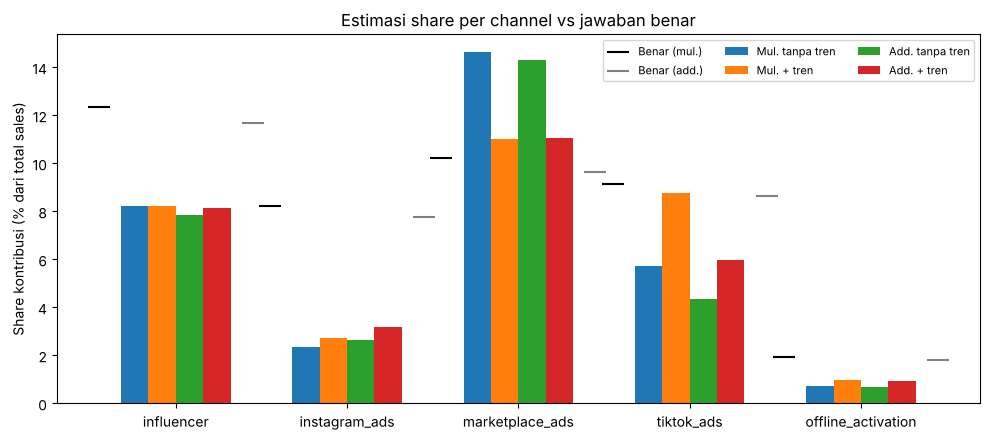

In [8]:
tags = ["multiplicative_notrend", "multiplicative_trend", "additive_notrend", "additive_trend"]
names = ["Mul. tanpa tren", "Mul. + tren", "Add. tanpa tren", "Add. + tren"]
chs = list(pick(tags[0]).index)
x = np.arange(len(chs)); w = 0.16
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (t, n) in enumerate(zip(tags, names)):
    ax.bar(x + (i - 1.5) * w, pick(t).est_share * 100, w, label=n)
tm = pick(tags[0]).true_share_with_season * 100
ta = pick(tags[2]).true_share_with_season * 100
ax.scatter(x - 0.45, tm, marker="_", s=250, c="k", label="Benar (mul.)", zorder=5)
ax.scatter(x + 0.45, ta, marker="_", s=250, c="grey", label="Benar (add.)", zorder=5)
ax.set_xticks(x); ax.set_xticklabels([c.replace("_S", "") for c in chs])
ax.set_ylabel("Share kontribusi (% dari total sales)"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Estimasi share per channel vs jawaban benar"); plt.tight_layout(); plt.show()

## 6. Kriteria lanjut ke dashboard

In [9]:
crit_cols = ["model", "K1_diagnostik_dgn_musim", "K2_hdi_dgn_musim", "K3_total_dgn_musim", "K4_roi_order_dgn_musim",
             "K2_hdi_tanpa_musim", "K3_total_tanpa_musim"]
sel = comp[comp.tag != "multiplicative_trend_hill"][crit_cols].set_index("model")
sel.columns = ["K1 diagnostik", "K2 benar di HDI (dgn musim)", "K3 total +-5pt (dgn musim)", "K4 urutan ROI", "K2 (tanpa musim)", "K3 (tanpa musim)"]
sel

,K1 diagnostik,K2 benar di HDI (dgn musim),K3 total +-5pt (dgn musim),K4 urutan ROI,K2 (tanpa musim),K3 (tanpa musim)
model,,,,,,
"Multiplikatif, tanpa tren",False,False,False,True,False,False
"Multiplikatif, + tren",False,False,False,True,False,False
"Aditif, tanpa tren",False,False,False,True,False,False
"Aditif, + tren",False,False,False,True,False,False
"Multiplikatif, tanpa tren (target_accept 0,97)",False,False,False,True,False,False
"Multiplikatif, + tren (target_accept 0,97)",True,False,False,True,False,False


## 7. Kesimpulan

**Yang kelihatan dari hasilnya**
- **Tren membantu per channel, tapi bukan akar masalah total share.** MAE share per channel turun dari ±3,7 ke ±2,3 poin (marketplace dan TikTok paling membaik), tapi total share media tetap ±32% vs 39,5-41,9% jawaban benar.
- **Gap total ±10 poin muncul juga di data aditif**, padahal struktur model dan data di situ sama-sama aditif. Jadi hipotesis "model aditif vs simulasi multiplikatif" bukan penyebab utamanya. Pilihan versi jawaban benar (dengan/tanpa pengali musim) hanya menggeser gap sekitar 2-3 poin.
- **Petunjuk penyebab**: pada fit multiplikatif + tren, intercept model menyerap ±64% dari sales, sedangkan baseline sebenarnya ±55%. Selisih ±9 poin kira-kira sebesar gap media. Ini konsisten dengan dugaan bahwa efek media yang stabil terserap intercept (spend harian selalu positif dan saturasi meratakan efeknya), tapi ini baru dugaan, belum diuji.
- **Instagram dan offline selalu di luar interval kredibel** di keempat model, jadi K2 gagal selisih satu channel (3 dari 5). Interval offline sempit tapi meleset, tanda model terlalu yakin.
- **Diagnostik**: pada `target_accept=0.9`, semua fit punya 3-27 divergences. Pada 0.97, fit + tren sehat (0 divergences, r_hat 1,005, ESS min 515). Fit tanpa tren pada 0.97: 0 divergences tapi ESS min 363 (<400).
- Saturasi Hill (sesuai simulasi) dicoba sekali dan **tidak konvergen** (r_hat 1,18, ESS 9), jadi tidak bisa dijadikan kesimpulan. Perlu reparameterisasi atau prior yang lebih ketat kalau mau dilanjutkan.

**Status kriteria lanjut ke dashboard**: K1 lolos hanya di fit + tren dengan target_accept 0.97, K4 lolos di semua model, K2 dan K3 belum lolos di model mana pun. Jadi sesuai aturan, belum lanjut ke dashboard.

**Batasan**: satu seed simulasi, satu siklus Ramadan dan Harbolnas, chain hanya 2, dan belum ada backtesting out-of-sample (split waktu), karena flag Harbolnas hanya muncul di akhir tahun.